In [1]:
import pandas as pd

# Collating results under /work/magroup/skrieger/Syndri/data/training_set_parameter_optimization/
# Wrote 80 rows: /work/magroup/skrieger/Syndri/data/training_set_parameter_optimization/all_training_set_similarity_summary.csv
# Wrote 3840 rows: /work/magroup/skrieger/Syndri/data/training_set_parameter_optimization/all_training_set_similarity_cell_metrics.csv
# Wrote 10240 rows: /work/magroup/skrieger/Syndri/data/training_set_parameter_optimization/all_training_set_similarity_gene_correlations.csv
# Wrote 3840 rows: /work/magroup/skrieger/Syndri/data/training_set_parameter_optimization/all_training_set_similarity_rank_agreement.csv
# Wrote 80 rows: /work/magroup/skrieger/Syndri/data/training_set_parameter_optimization/all_training_set_similarity_classifier.csv
# No rows found for per_gene
# Copied manifest: /work/magroup/skrieger/Syndri/data/training_set_parameter_optimization/submitted_grid_manifest.tsv
results = pd.read_csv('/work/magroup/skrieger/Syndri/data/training_set_parameter_optimization/all_training_set_similarity_summary.csv',sep=',')
manifest = pd.read_csv('/work/magroup/skrieger/Syndri/data/training_set_parameter_optimization/submitted_grid_manifest.tsv',sep='\t')
# results.sort_values(by='')
results = results.sort_values(by='positive_mean_expression_median_pearson',ascending=False).merge(manifest,on='config_id')
results.columns

Index(['task_id', 'task_dir', 'config_id',
       'detected_genes_per_cell_median_normalized_wasserstein',
       'total_counts_per_cell_median_normalized_wasserstein',
       'max_count_per_cell_median_normalized_wasserstein',
       'detection_fraction_median_pearson',
       'positive_mean_expression_median_pearson',
       'positive_median_expression_median_pearson',
       'top_50_median_overlap_fraction', 'top_100_median_overlap_fraction',
       'top_277_median_overlap_fraction', 'classifier_auc',
       'classifier_accuracy', 'classifier_auc_distance_from_0p5',
       'spatial_path', 'single_cell_path', 'sample_admixture_from_neighbors',
       'spatial_layer', 'single_cell_raw_layer', 'spatial_cell_type_key',
       'single_cell_cell_type_key', 'coord_x', 'coord_y', 'tissue_key',
       'neighbor_cell_type_key', 'neighbor_dict_key', 'neighbor_id_col',
       'build_neighbor_dict', 'group_mode', 'min_cells_per_group',
       'max_cells_per_domain', 'classifier', 'classifier_by_

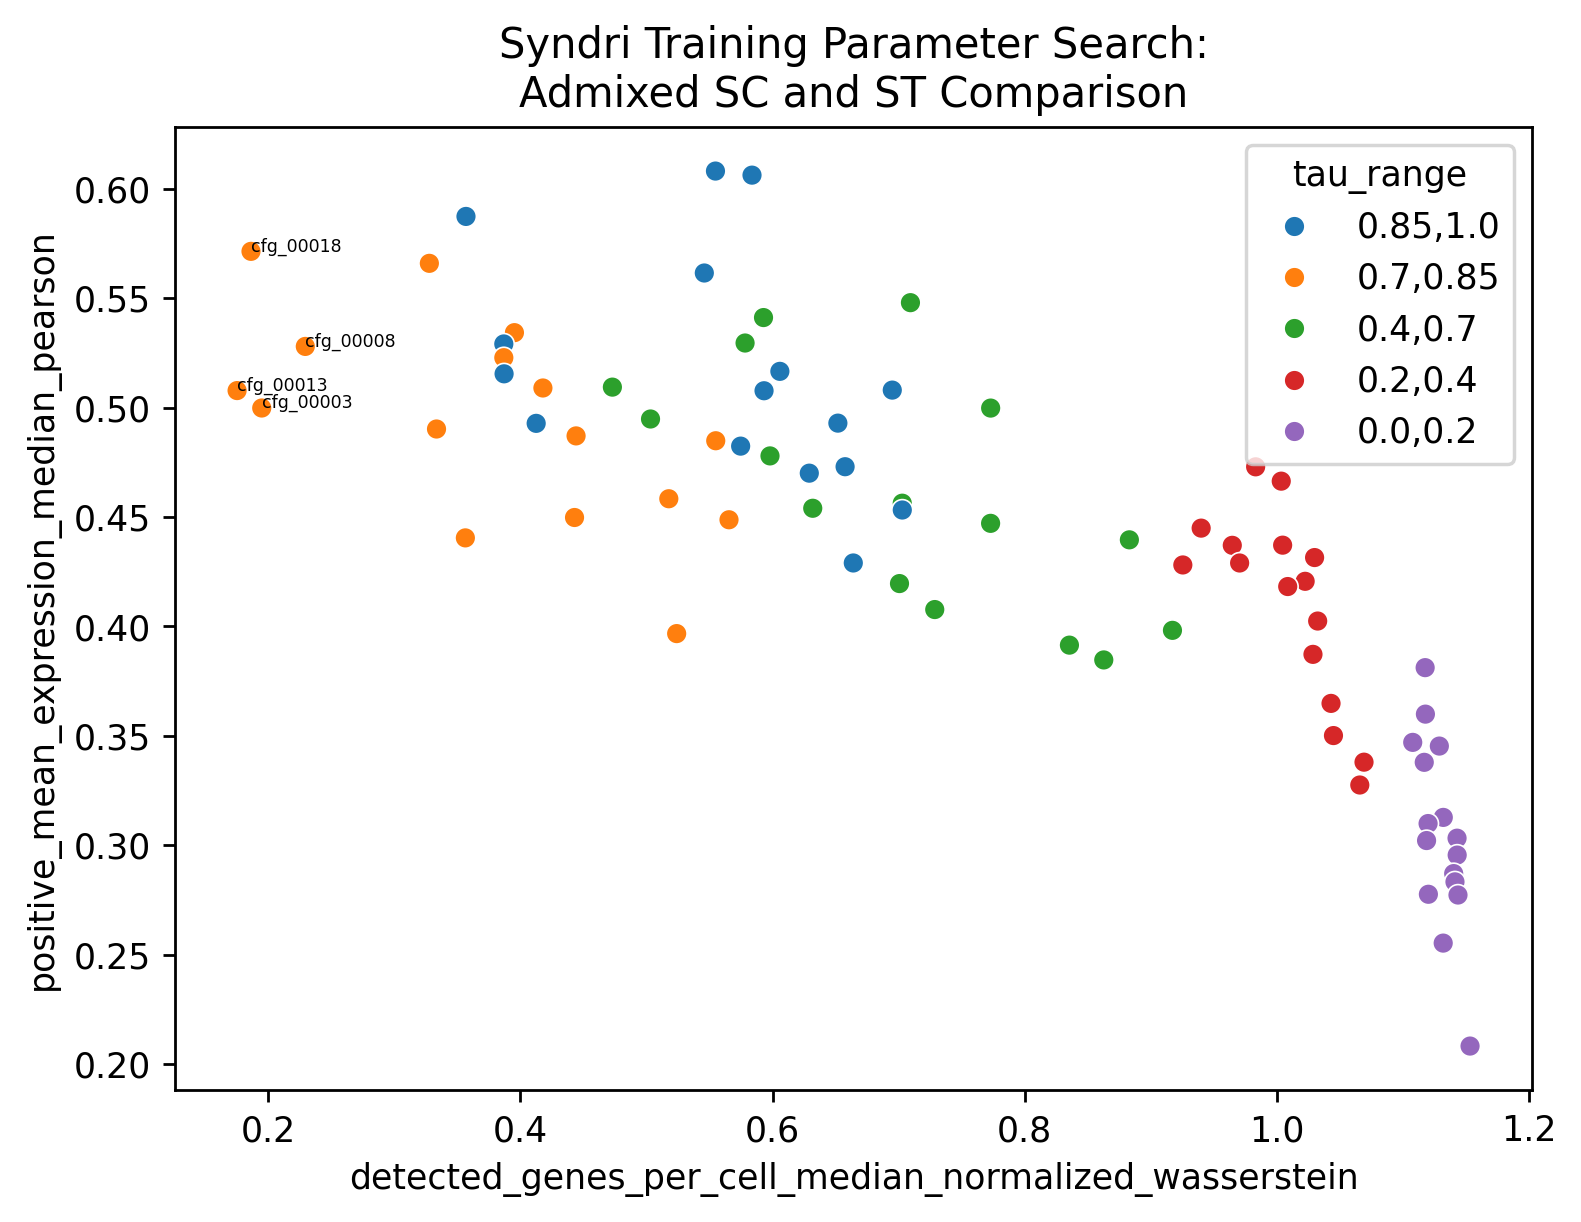

,task_id,task_dir,config_id,detected_genes_per_cell_median_normalized_wasserstein,total_counts_per_cell_median_normalized_wasserstein,max_count_per_cell_median_normalized_wasserstein,detection_fraction_median_pearson,positive_mean_expression_median_pearson,positive_median_expression_median_pearson,top_50_median_overlap_fraction,...,random_state,admixture_scales,k_neighbors,min_sampled_transcript_threshold,min_source_transcript_count,use_same_cell_type_neighbors,only_sample_unexpressed_genes,mask_out_random_genes,mask_out_frac,tau_range
18,13,/work/magroup/skrieger/Syndri/data/training_se...,cfg_00013,0.175146,0.248464,0.750251,0.812131,0.507840,0.327203,0.63,...,0,1.0,5,10,10,True,True,False,0.0,"0.7,0.85"
3,18,/work/magroup/skrieger/Syndri/data/training_se...,cfg_00018,0.186179,0.330146,0.982968,0.810350,0.571492,0.432655,0.65,...,0,1.0,5,10,10,True,False,False,0.0,"0.7,0.85"
20,3,/work/magroup/skrieger/Syndri/data/training_se...,cfg_00003,0.194700,0.292238,0.775553,0.809190,0.499867,0.300955,0.63,...,0,1.0,5,10,10,False,True,False,0.0,"0.7,0.85"
11,8,/work/magroup/skrieger/Syndri/data/training_se...,cfg_00008,0.229266,0.343028,0.884067,0.809978,0.528025,0.371841,0.63,...,0,1.0,5,10,10,False,False,False,0.0,"0.7,0.85"
4,38,/work/magroup/skrieger/Syndri/data/training_se...,cfg_00038,0.327703,0.533382,1.546576,0.795063,0.566012,0.455714,0.66,...,0,1.0,10,10,10,True,False,False,0.0,"0.7,0.85"


In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

x_col = 'detected_genes_per_cell_median_normalized_wasserstein'
# y_col = 'total_counts_per_cell_median_normalized_wasserstein'
y_col = 'positive_mean_expression_median_pearson'
hue_col = 'tau_range'
annot_col = 'config_id'

fig,ax = plt.subplots(figsize=(7,5),dpi=250)
ax=sns.scatterplot(data=results,x=x_col,y=y_col,hue=hue_col)
for _, row in results.iterrows():
    if row[x_col] < 0.3:
        ax.text(
            row[x_col], row[y_col], row[annot_col], horizontalalignment="left",fontsize=5
        )

ax.set_title('Syndri Training Parameter Search:\nAdmixed SC and ST Comparison')
plt.show()
results.sort_values(by=x_col).head(5)


In [117]:
results = pd.read_csv('/work/magroup/skrieger/Syndri/data/training_set_parameter_optimization/all_training_set_similarity_cell_metrics.csv',sep=',')
manifest = pd.read_csv('/work/magroup/skrieger/Syndri/data/training_set_parameter_optimization/submitted_grid_manifest.tsv',sep='\t')
cols_to_use = manifest.columns.difference(results.columns).tolist() + ['config_id']

results = results.merge(manifest[cols_to_use],on='config_id')
results['config_id'].value_counts()


config_id
cfg_00000    48
cfg_00001    48
cfg_00058    48
cfg_00057    48
cfg_00056    48
             ..
cfg_00025    48
cfg_00024    48
cfg_00023    48
cfg_00022    48
cfg_00079    48
Name: count, Length: 80, dtype: int64

In [ ]:
results

0                                          all
1                                          all
2                                          all
3       CD4-positive, alpha-beta memory T cell
4       CD4-positive, alpha-beta memory T cell
                         ...                  
3835               plasmacytoid dendritic cell
3836               plasmacytoid dendritic cell
3837                        smooth muscle cell
3838                        smooth muscle cell
3839                        smooth muscle cell
Name: group, Length: 3840, dtype: object

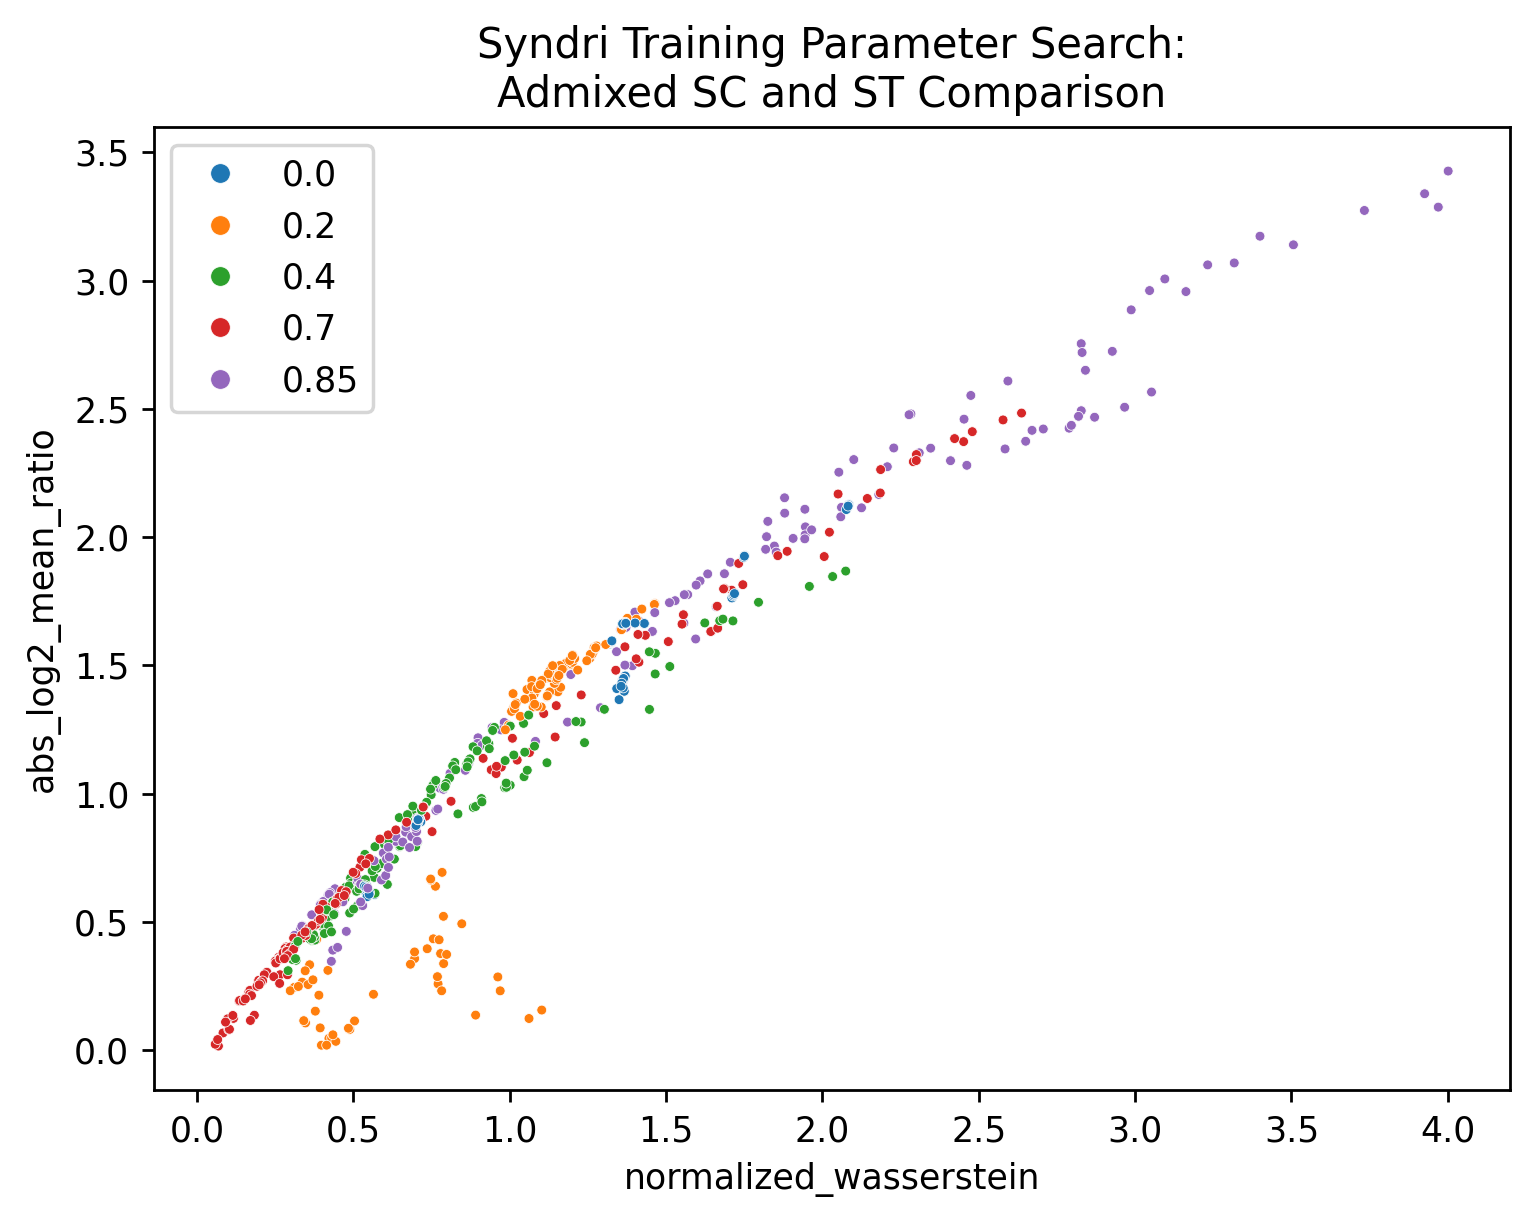

,task_id,task_dir,config_id,spatial_path,single_cell_path,spatial_layer,single_cell_raw_layer,single_cell_admix_layer,single_cell_sim_layer,admixture_scale,...,classifier_max_cells_per_domain,classifier_max_features,group_mode,max_cells_per_domain,min_cells_per_group,random_state,single_cell_cell_type_key,spatial_cell_type_key,tau_range,top_gene_counts
3010,62,/work/magroup/skrieger/Syndri/data/training_se...,cfg_00062,/work/magroup/skrieger/Syndri/data/xenium_nois...,/work/magroup/skrieger/Syndri/data/trainsets/c...,X,X,generated_from_neighbors,NaN,1.0,...,5000,2000,both,0,20,0,cell_type,harmony_cell_type,"0.4,0.7","50,100,500"
627,13,/work/magroup/skrieger/Syndri/data/training_se...,cfg_00013,/work/magroup/skrieger/Syndri/data/xenium_nois...,/work/magroup/skrieger/Syndri/data/trainsets/c...,X,X,generated_from_neighbors,NaN,1.0,...,5000,2000,both,0,20,0,cell_type,harmony_cell_type,"0.7,0.85","50,100,500"
1570,32,/work/magroup/skrieger/Syndri/data/training_se...,cfg_00032,/work/magroup/skrieger/Syndri/data/xenium_nois...,/work/magroup/skrieger/Syndri/data/trainsets/c...,X,X,generated_from_neighbors,NaN,1.0,...,5000,2000,both,0,20,0,cell_type,harmony_cell_type,"0.4,0.7","50,100,500"
1377,28,/work/magroup/skrieger/Syndri/data/training_se...,cfg_00028,/work/magroup/skrieger/Syndri/data/xenium_nois...,/work/magroup/skrieger/Syndri/data/trainsets/c...,X,X,generated_from_neighbors,NaN,1.0,...,5000,2000,both,0,20,0,cell_type,harmony_cell_type,"0.7,0.85","50,100,500"
1150,23,/work/magroup/skrieger/Syndri/data/training_se...,cfg_00023,/work/magroup/skrieger/Syndri/data/xenium_nois...,/work/magroup/skrieger/Syndri/data/trainsets/c...,X,X,generated_from_neighbors,NaN,1.0,...,5000,2000,both,0,20,0,cell_type,harmony_cell_type,"0.7,0.85","50,100,500"


In [129]:
x_col = 'normalized_wasserstein'
y_col = 'abs_log2_mean_ratio'
# y_col = 'positive_mean_expression_median_pearson'
hue_col = 'tau_low'
annot_col = 'config_id'

fig,ax = plt.subplots(figsize=(7,5),dpi=250)
ax=sns.scatterplot(data=results[results['group'].str.contains('T')],x=x_col,y=y_col,hue=hue_col,s=8,palette='tab10')
# for _, row in results.iterrows():
#     if row[x_col] < 0.3:
#         ax.text(
#             row[x_col], row[y_col], row[annot_col], horizontalalignment="left",fontsize=5
#         )
ax.legend(markerscale=2)
ax.set_title('Syndri Training Parameter Search:\nAdmixed SC and ST Comparison')
plt.show()
results.sort_values(by=x_col).head(5)

In [131]:
pd.read_csv('/work/magroup/skrieger/Syndri/data/training_set_parameter_optimization/all_training_set_similarity_gene_correlations.csv').columns

Index(['task_id', 'task_dir', 'config_id', 'spatial_path', 'single_cell_path',
       'spatial_layer', 'single_cell_raw_layer', 'single_cell_admix_layer',
       'single_cell_sim_layer', 'admixture_scale',
       'sample_admixture_from_neighbors', 'neighbor_dict_key',
       'neighbor_id_col', 'build_neighbor_dict', 'k_neighbors', 'coord_x',
       'coord_y', 'tissue_key', 'neighbor_cell_type_key',
       'min_source_transcript_count', 'use_same_cell_type_neighbors',
       'min_sampled_transcript_threshold', 'only_sample_unexpressed_genes',
       'mask_out_random_genes', 'mask_out_frac', 'tau_low', 'tau_high',
       'admixture_repeats', 'group', 'metric', 'correlation_method',
       'correlation', 'pvalue', 'n_genes'],
      dtype='object')